# CAM 방법 · 층 비교 — 합성 비율별 위치 성능 재계산

`synthetic_resnet_experiment.ipynb` 에서 **이미 학습·저장한 20개 모델**(`outputs/synth_exp/models/`)을 그대로 불러와
Grad-CAM 외의 방법(GradCAM++ / HiResCAM / LayerCAM / XGradCAM)과 더 얕은 층(`layer3`, 14×14)으로 **Pixel AUROC · AUPRO 만 다시 계산**한다.
**재학습은 없다** — CAM 은 학습된 모델에 사후 적용하는 시각화이므로 모델 가중치(= F2 등 분류 성능)는 그대로다.

기존 Grad-CAM 은 `layer4[-1]` 의 **7×7** 맵이라 작은 결함(1024 중 약 40px)에는 너무 거칠다. 지표가 낮은 이유가 모델이 아니라 맵 해상도일 수 있어서 확인한다.

주의
- 방법·층이 다르면 지표 **절대값은 직접 비교하지 않는다**(맵의 매끄러움에 따라 달라짐). 볼 것은 "같은 방법 안에서 합성 비율에 따른 변화"가 방법을 바꿔도 유지되는가이다.
- 평가는 real test 의 결함 19장(합성 0장). 시드 5개·결함 19장이라 표본이 작다.

In [1]:
import os, sys, time
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() or not (ROOT / "splits").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("레포 루트를 찾지 못함")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import torch
from scipy import stats
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, HiResCAM, LayerCAM, XGradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

from src.common.paths import SYNTH_EXP_DIR
from src.supervised.data import list_records
from src.supervised.dataset import val_transform
from src.supervised.model import build_model_bin
from src.supervised.loc_eval import load_mask, inv_normalize, _compute_pixel_metrics

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

W1105 11:26:43.347000 20440 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


device: cuda


## 1. 설정

In [2]:
METHODS = {"GradCAM": GradCAM, "GradCAM++": GradCAMPlusPlus, "HiResCAM": HiResCAM,
           "LayerCAM": LayerCAM, "XGradCAM": XGradCAM}
LAYERS = ["layer3", "layer4"]          # layer3 = 14x14, layer4 = 7x7 (기존 Grad-CAM 은 layer4)
RUNS_CSV = os.path.join(SYNTH_EXP_DIR, "runs.csv")                 # 학습 때 저장된 결과(검증용)
MODEL_DIR = os.path.join(SYNTH_EXP_DIR, "models")
OUT_CSV = os.path.join(SYNTH_EXP_DIR, "cam_methods.csv")           # 이 노트북의 결과(이어서 실행 가능)

runs = pd.read_csv(RUNS_CSV)
RATIOS = sorted(runs["ratio"].unique()); SEEDS = sorted(runs["seed"].unique())
def model_path(ratio, seed): return os.path.join(MODEL_DIR, f"r{ratio:.2f}_s{seed}.pth")
missing = [model_path(r, s) for r in RATIOS for s in SEEDS if not os.path.exists(model_path(r, s))]
assert not missing, f"모델 파일 없음: {missing[:3]}"
print("ratios", RATIOS, "| seeds", SEEDS, "| methods", list(METHODS), "| layers", LAYERS)

ratios [np.float64(0.0), np.float64(0.25), np.float64(0.5), np.float64(1.0)] | seeds [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)] | methods ['GradCAM', 'GradCAM++', 'HiResCAM', 'LayerCAM', 'XGradCAM'] | layers ['layer3', 'layer4']


## 2. test 결함 19장 준비 (이미지 텐서 + GT 마스크)

In [3]:
CLASS_NAMES = ["good", "type1", "type2", "type3", "type4", "type5"]
test_recs = [{"path": r["path"], "type": r["class"], "label": 0 if r["class"] == "good" else 1, "mask": r["mask"]}
             for r in list_records("test", CLASS_NAMES)]
defects = [r for r in test_recs if r["label"] == 1]
X = torch.stack([val_transform(Image.open(r["path"]).convert("RGB")) for r in defects]).to(device)   # (19,3,224,224)
M = np.stack([load_mask(r["mask"]) for r in defects])                                                # (19,224,224)
types = np.array([r["type"] for r in defects])
print("결함", len(defects), "장 |", pd.Series(types).value_counts().sort_index().to_dict())

def load_model(ratio, seed):
    m = build_model_bin("resnet18").to(device)
    m.load_state_dict(torch.load(model_path(ratio, seed), map_location=device)); m.eval()
    return m

def cam_maps(model, method, layer, x=X):
    target_layer = getattr(model, layer)[-1]
    with METHODS[method](model=model, target_layers=[target_layer]) as cam:
        return cam(input_tensor=x, targets=[ClassifierOutputTarget(1)] * len(x))      # (N,224,224), 샘플별 0~1 정규화

결함 19 장 | {'type1': 4, 'type2': 4, 'type3': 5, 'type4': 3, 'type5': 3}


## 3. 재계산 — (모델 20개) × (방법 5) × (층 2)

결과를 `cam_methods.csv` 에 누적 저장(이어서 실행 가능). 첫 줄 검증: **GradCAM + layer4 는 기존 `runs.csv` 의 pixel_auroc / aupro 와 같아야 한다**(같은 방법이므로).

In [4]:
done = pd.read_csv(OUT_CSV) if os.path.exists(OUT_CSV) else pd.DataFrame()
rows = done.to_dict("records")
done_keys = {(float(r["ratio"]), int(r["seed"]), r["method"], r["layer"]) for r in rows}
t0 = time.time()
for seed in SEEDS:
    for ratio in RATIOS:
        todo = [(m, l) for m in METHODS for l in LAYERS if (float(ratio), int(seed), m, l) not in done_keys]
        if not todo:
            continue
        model = load_model(ratio, seed)
        for m, l in todo:
            cams = cam_maps(model, m, l)
            res = _compute_pixel_metrics(list(cams), list(M))
            rows.append(dict(ratio=ratio, seed=seed, method=m, layer=l, pixel_auroc=res["pixel_auroc"], aupro=res["aupro"]))
        pd.DataFrame(rows).to_csv(OUT_CSV, index=False)
        print(f"ratio={ratio:<4} seed={seed} 완료 ({len(rows)} rows, {time.time()-t0:.0f}s)")
        del model; torch.cuda.empty_cache()

res = pd.DataFrame(rows)
# 검증: 기존 Grad-CAM(layer4) 결과 재현 여부
chk = res[(res.method == "GradCAM") & (res.layer == "layer4")].merge(runs[["ratio", "seed", "pixel_auroc", "aupro"]],
                                                                    on=["ratio", "seed"], suffixes=("", "_orig"))
print(f"\n[검증] GradCAM/layer4 재현: 최대 |Δ pixel_auroc| = {(chk.pixel_auroc - chk.pixel_auroc_orig).abs().max():.2e}, "
      f"|Δ aupro| = {(chk.aupro - chk.aupro_orig).abs().max():.2e}  (n={len(chk)})")

ratio=0.25 seed=1 완료 (60 rows, 8s)
ratio=0.5  seed=1 완료 (70 rows, 14s)
ratio=1.0  seed=1 완료 (80 rows, 20s)
ratio=0.0  seed=2 완료 (90 rows, 26s)
ratio=0.25 seed=2 완료 (100 rows, 33s)
ratio=0.5  seed=2 완료 (110 rows, 40s)
ratio=1.0  seed=2 완료 (120 rows, 50s)
ratio=0.0  seed=3 완료 (130 rows, 61s)
ratio=0.25 seed=3 완료 (140 rows, 70s)
ratio=0.5  seed=3 완료 (150 rows, 80s)
ratio=1.0  seed=3 완료 (160 rows, 84s)
ratio=0.0  seed=4 완료 (170 rows, 90s)
ratio=0.25 seed=4 완료 (180 rows, 97s)
ratio=0.5  seed=4 완료 (190 rows, 103s)
ratio=1.0  seed=4 완료 (200 rows, 109s)

[검증] GradCAM/layer4 재현: 최대 |Δ pixel_auroc| = 1.10e-04, |Δ aupro| = 1.67e-04  (n=20)


## 4. 결과 — 방법·층별로 합성 비율에 따른 변화

각 칸은 시드 5회의 평균 ± 표준편차. `Δ(0.25)` 는 합성 없음(0.0) 대비 0.25 의 평균 차이이고 `p` 는 시드로 짝지은 t-test.

In [5]:
res = pd.read_csv(OUT_CSV)
def table(metric):
    out = []
    for (m, l), g in res.groupby(["method", "layer"], sort=False):
        piv = g.pivot(index="seed", columns="ratio", values=metric)
        row = {"방법": m, "층": l}
        for r in RATIOS:
            row[f"{r}"] = f"{piv[r].mean():.3f} ± {piv[r].std(ddof=1):.3f}"
        for r in RATIOS[1:]:
            d = piv[r] - piv[RATIOS[0]]
            row[f"Δ({r})"] = f"{d.mean():+.3f} (p={stats.ttest_rel(piv[r], piv[RATIOS[0]]).pvalue:.2f})"
        out.append(row)
    return pd.DataFrame(out)

print("=== Pixel AUROC ===");  display(table("pixel_auroc"))
print("=== AUPRO ===");        display(table("aupro"))

=== Pixel AUROC ===


,방법,층,0.0,0.25,0.5,1.0,Δ(0.25),Δ(0.5),Δ(1.0)
0,GradCAM,layer3,0.928 ± 0.042,0.937 ± 0.050,0.952 ± 0.024,0.936 ± 0.066,+0.008 (p=0.68),+0.024 (p=0.46),+0.008 (p=0.85)
1,GradCAM,layer4,0.807 ± 0.095,0.902 ± 0.043,0.876 ± 0.015,0.903 ± 0.040,+0.095 (p=0.05),+0.069 (p=0.22),+0.096 (p=0.11)
2,GradCAM++,layer3,0.919 ± 0.032,0.952 ± 0.025,0.962 ± 0.014,0.969 ± 0.009,+0.033 (p=0.07),+0.044 (p=0.03),+0.050 (p=0.04)
3,GradCAM++,layer4,0.824 ± 0.067,0.925 ± 0.021,0.901 ± 0.026,0.937 ± 0.016,+0.100 (p=0.04),+0.077 (p=0.04),+0.113 (p=0.01)
4,HiResCAM,layer3,0.871 ± 0.085,0.948 ± 0.015,0.950 ± 0.032,0.953 ± 0.035,+0.077 (p=0.14),+0.079 (p=0.17),+0.082 (p=0.14)
5,HiResCAM,layer4,0.807 ± 0.095,0.902 ± 0.043,0.876 ± 0.015,0.903 ± 0.040,+0.095 (p=0.05),+0.069 (p=0.22),+0.096 (p=0.11)
6,LayerCAM,layer3,0.914 ± 0.051,0.970 ± 0.019,0.967 ± 0.009,0.982 ± 0.004,+0.056 (p=0.06),+0.053 (p=0.08),+0.067 (p=0.04)
7,LayerCAM,layer4,0.822 ± 0.065,0.923 ± 0.023,0.903 ± 0.025,0.937 ± 0.014,+0.101 (p=0.05),+0.081 (p=0.03),+0.115 (p=0.01)
8,XGradCAM,layer3,0.928 ± 0.048,0.964 ± 0.017,0.979 ± 0.006,0.959 ± 0.038,+0.036 (p=0.12),+0.051 (p=0.09),+0.031 (p=0.33)
9,XGradCAM,layer4,0.807 ± 0.095,0.902 ± 0.043,0.876 ± 0.015,0.903 ± 0.040,+0.095 (p=0.05),+0.069 (p=0.22),+0.096 (p=0.11)


=== AUPRO ===


,방법,층,0.0,0.25,0.5,1.0,Δ(0.25),Δ(0.5),Δ(1.0)
0,GradCAM,layer3,0.797 ± 0.098,0.873 ± 0.071,0.899 ± 0.047,0.883 ± 0.092,+0.076 (p=0.15),+0.102 (p=0.19),+0.086 (p=0.25)
1,GradCAM,layer4,0.556 ± 0.181,0.808 ± 0.049,0.806 ± 0.045,0.815 ± 0.030,+0.252 (p=0.03),+0.250 (p=0.05),+0.260 (p=0.04)
2,GradCAM++,layer3,0.754 ± 0.087,0.895 ± 0.011,0.911 ± 0.023,0.916 ± 0.023,+0.140 (p=0.02),+0.157 (p=0.02),+0.162 (p=0.02)
3,GradCAM++,layer4,0.558 ± 0.146,0.782 ± 0.057,0.761 ± 0.031,0.821 ± 0.055,+0.224 (p=0.07),+0.203 (p=0.04),+0.263 (p=0.00)
4,HiResCAM,layer3,0.700 ± 0.166,0.900 ± 0.022,0.917 ± 0.029,0.916 ± 0.045,+0.200 (p=0.06),+0.217 (p=0.06),+0.216 (p=0.05)
5,HiResCAM,layer4,0.556 ± 0.181,0.808 ± 0.049,0.806 ± 0.045,0.815 ± 0.030,+0.252 (p=0.03),+0.250 (p=0.05),+0.260 (p=0.04)
6,LayerCAM,layer3,0.762 ± 0.122,0.923 ± 0.031,0.918 ± 0.018,0.945 ± 0.011,+0.160 (p=0.04),+0.156 (p=0.05),+0.183 (p=0.03)
7,LayerCAM,layer4,0.551 ± 0.136,0.775 ± 0.064,0.757 ± 0.029,0.821 ± 0.046,+0.224 (p=0.06),+0.206 (p=0.03),+0.270 (p=0.00)
8,XGradCAM,layer3,0.797 ± 0.121,0.919 ± 0.015,0.941 ± 0.023,0.929 ± 0.046,+0.122 (p=0.08),+0.145 (p=0.07),+0.132 (p=0.08)
9,XGradCAM,layer4,0.556 ± 0.181,0.808 ± 0.049,0.806 ± 0.045,0.815 ± 0.030,+0.252 (p=0.03),+0.250 (p=0.05),+0.260 (p=0.04)


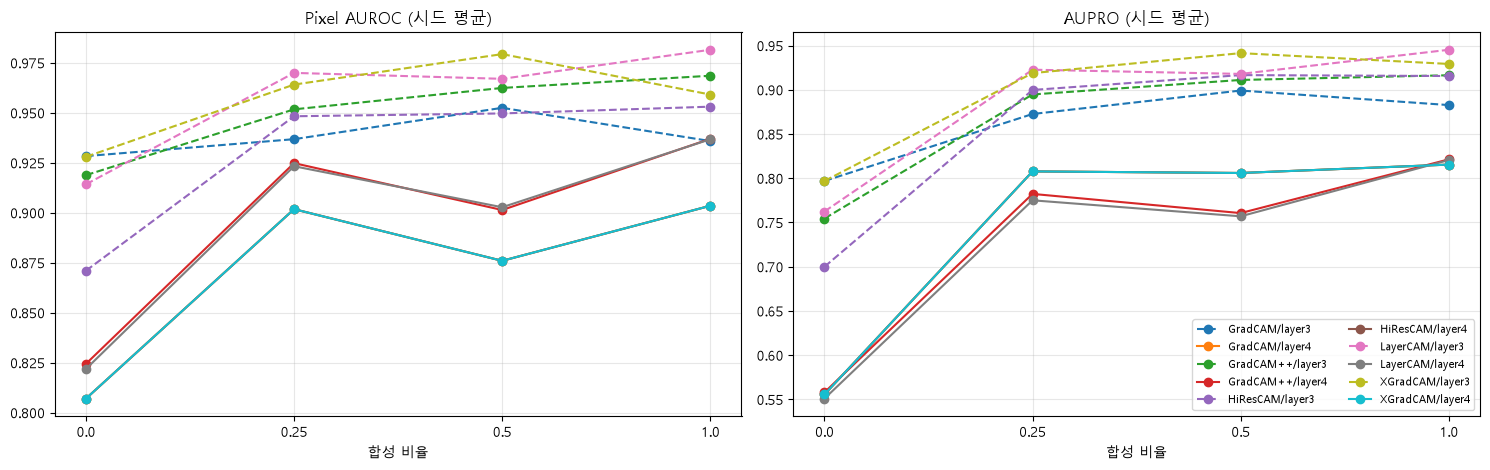

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
for a, (k, name) in zip(axs, [("pixel_auroc", "Pixel AUROC"), ("aupro", "AUPRO")]):
    for (m, l), g in res.groupby(["method", "layer"], sort=False):
        mean = g.groupby("ratio")[k].mean()
        a.plot(range(len(mean)), mean.values, marker="o", ls="-" if l == "layer4" else "--", label=f"{m}/{l}")
    a.set_xticks(range(len(RATIOS))); a.set_xticklabels([str(r) for r in RATIOS])
    a.set_xlabel("합성 비율"); a.set_title(f"{name} (시드 평균)"); a.grid(alpha=.3)
axs[1].legend(fontsize=8, ncol=2, loc="lower right")
plt.tight_layout(); plt.show()

## 5. 눈으로 보기 — 같은 test 이미지, 방법·층별 맵

시드 하나(`VIZ_SEED`)의 모델로, 유형별 test 첫 장(고정 규칙)을 합성 없음 / 0.25 로 비교. 열: 원본 / GT / 각 (방법, 층).

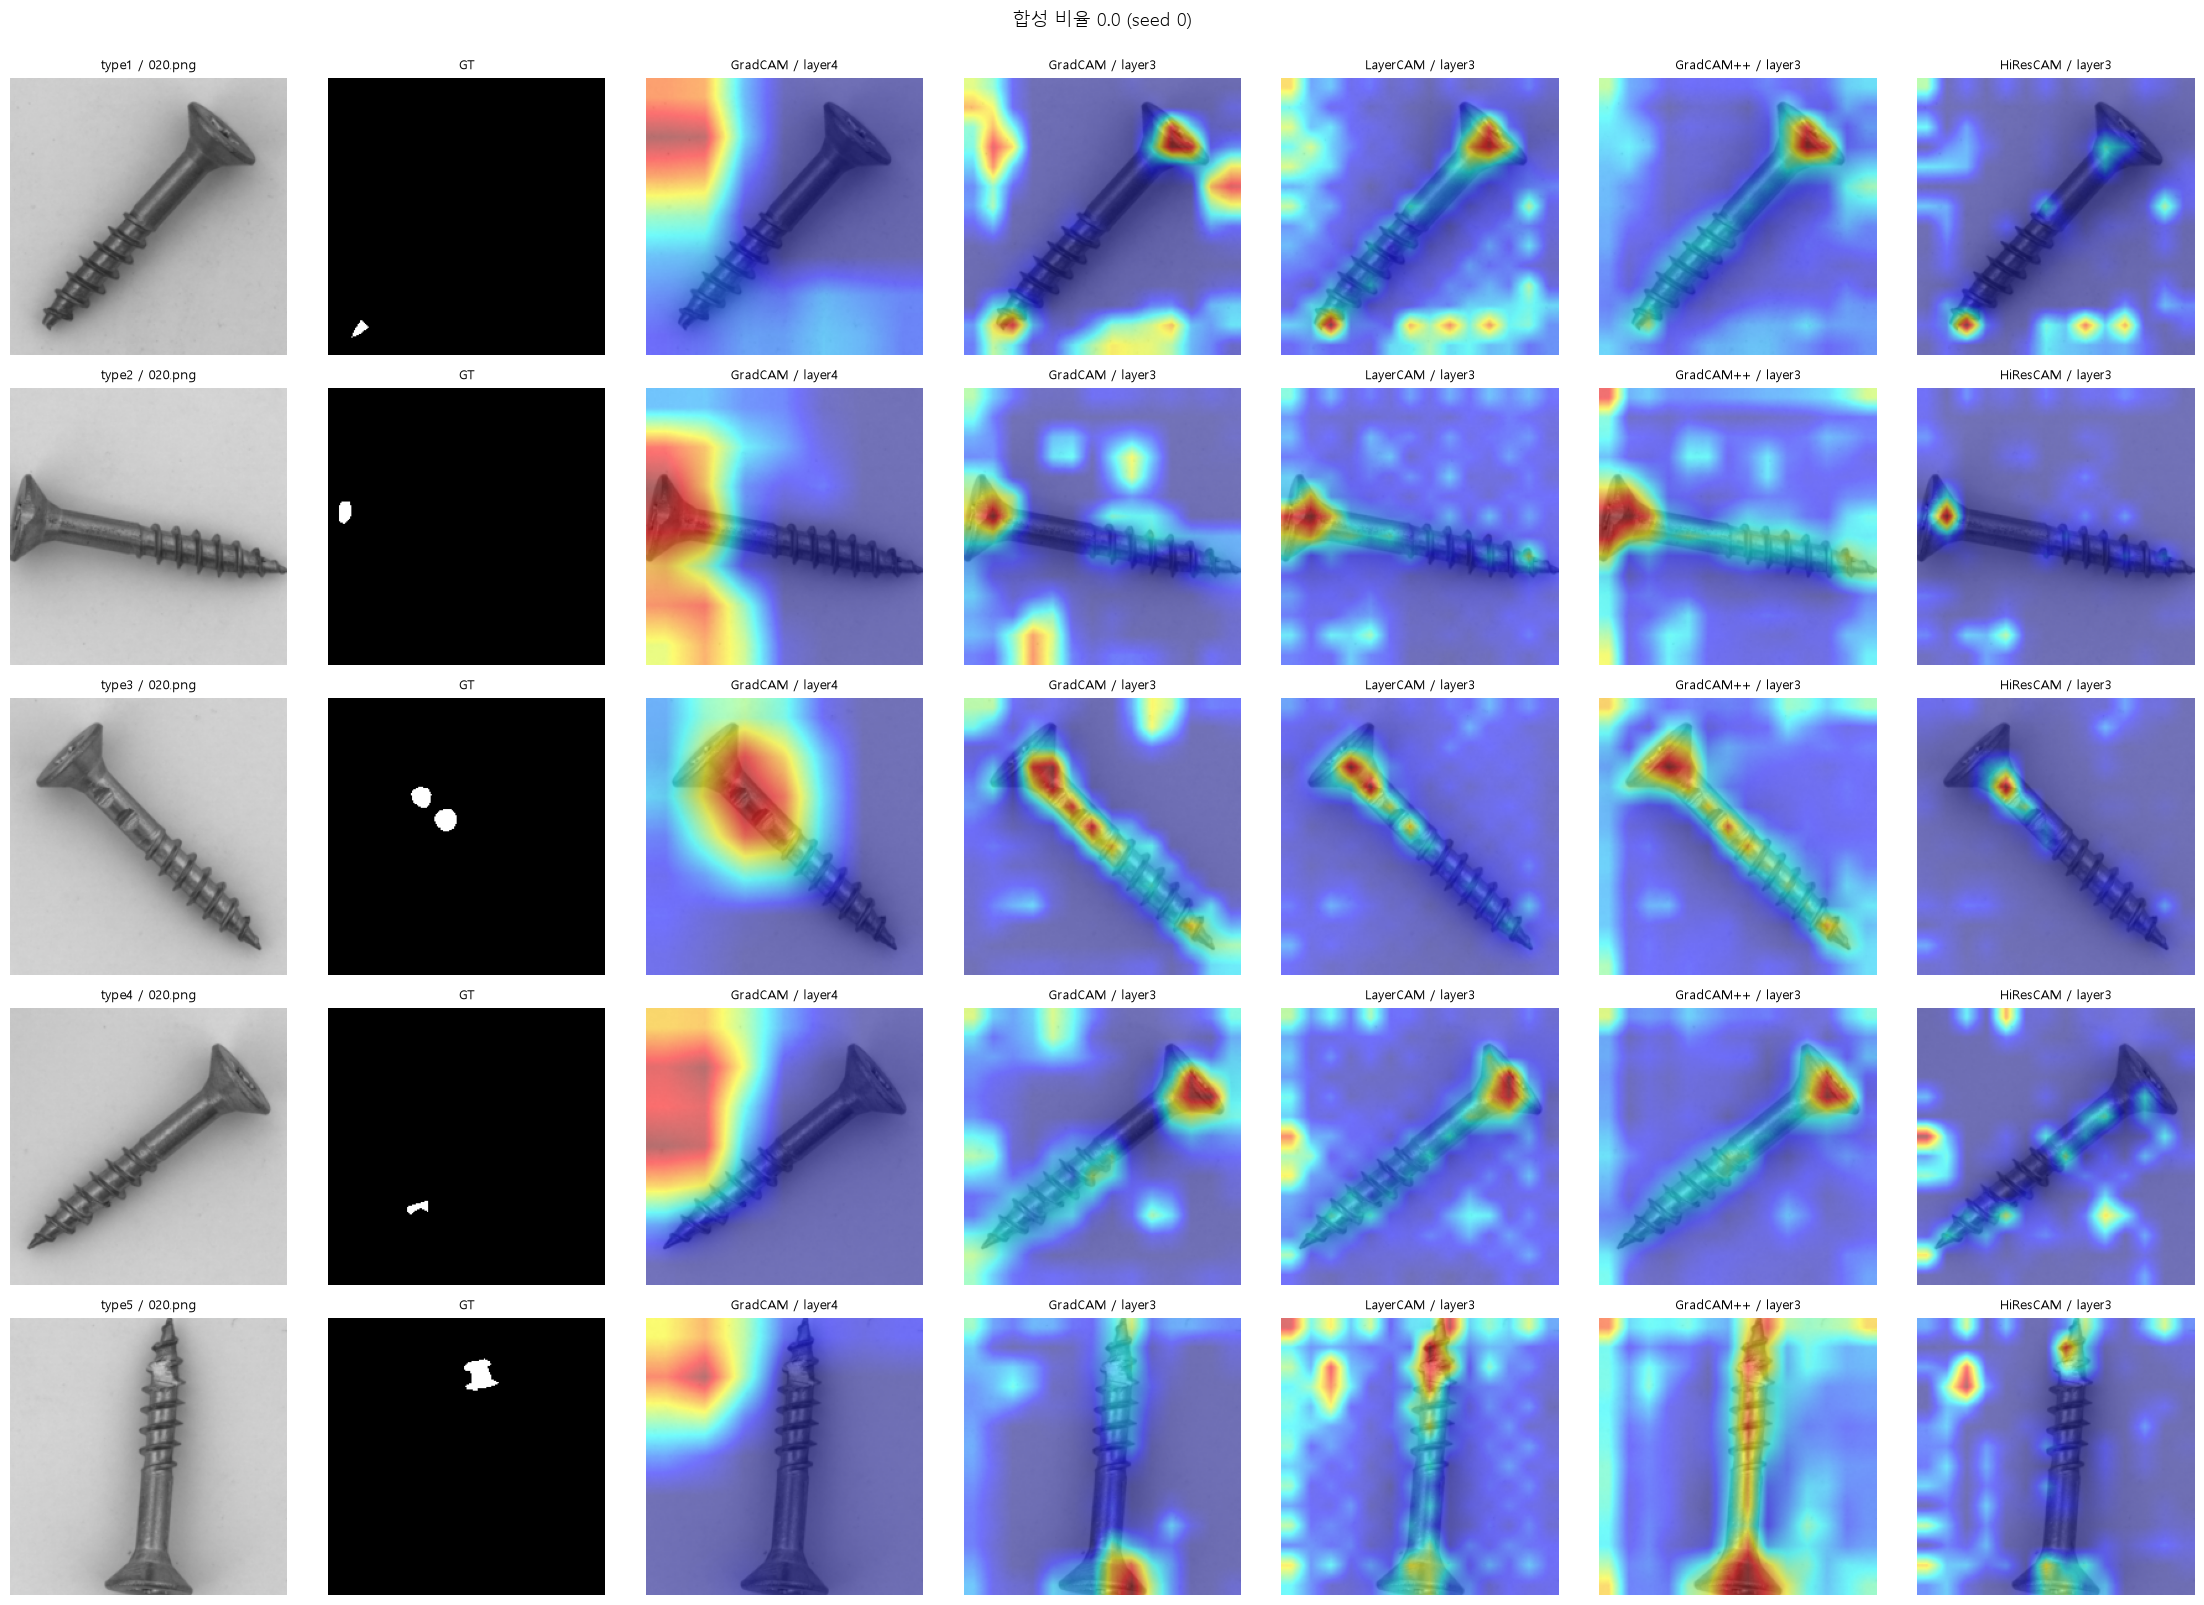

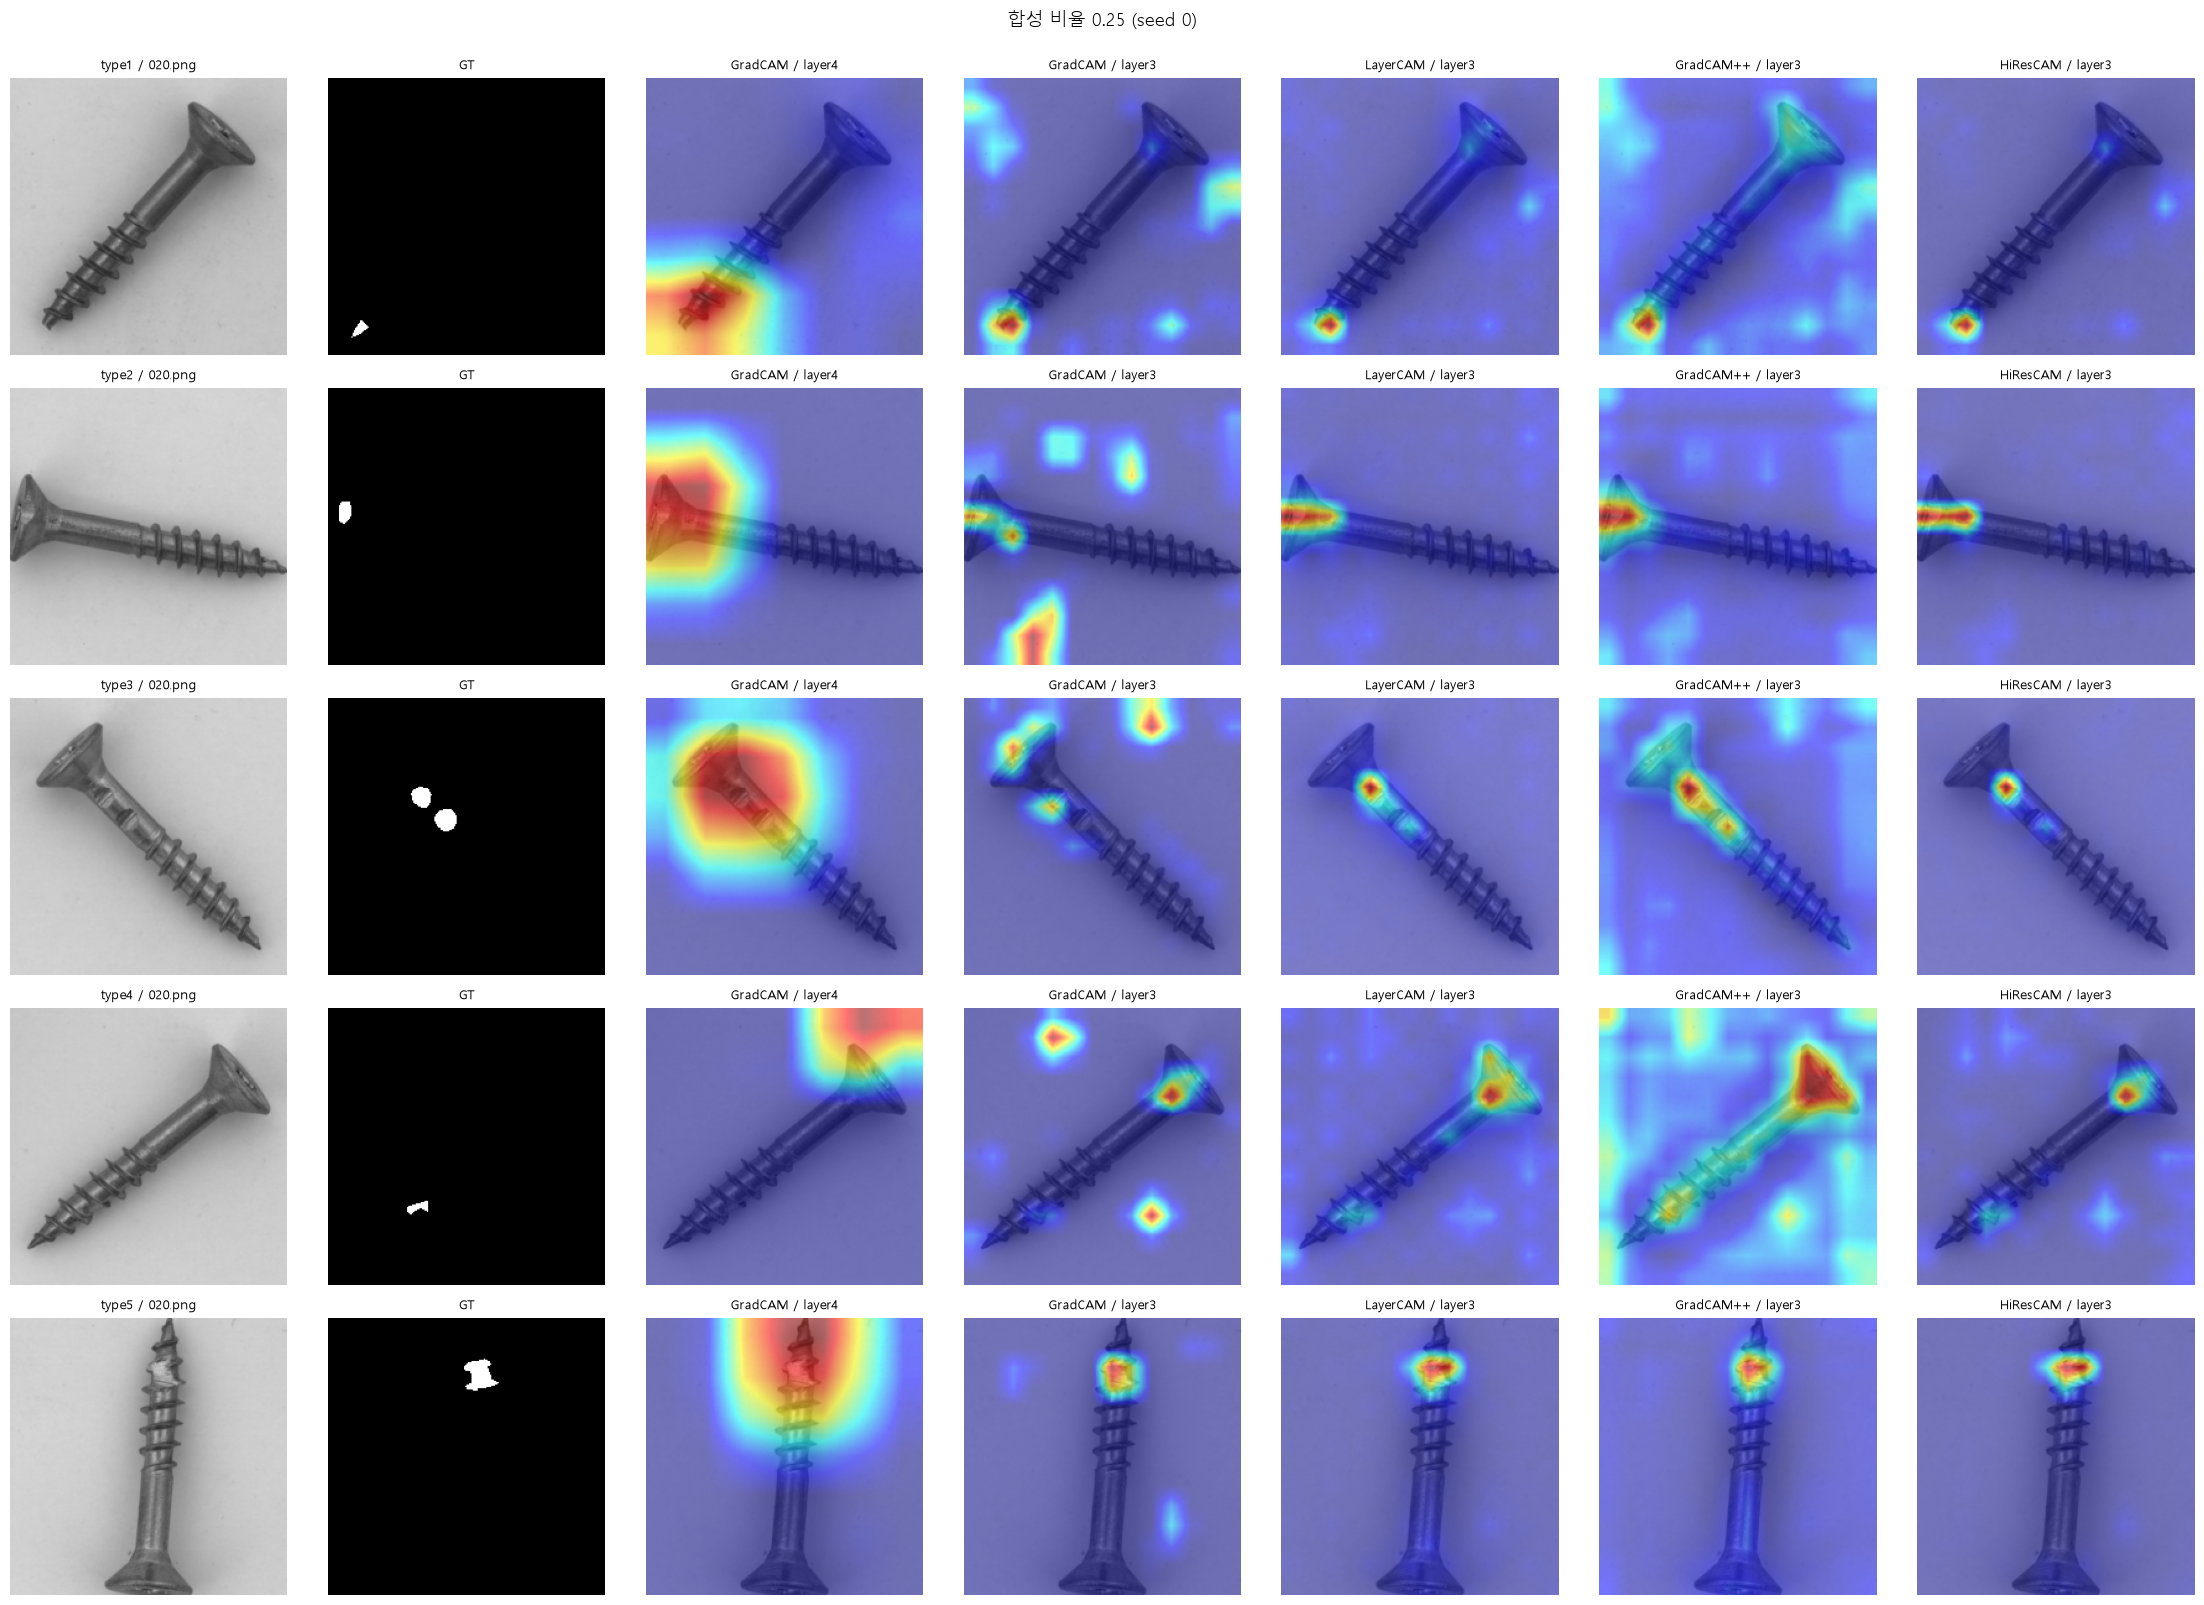

: 

In [ ]:
VIZ_SEED = SEEDS[0]
VIZ_COMBOS = [("GradCAM", "layer4"), ("GradCAM", "layer3"), ("LayerCAM", "layer3"), ("GradCAM++", "layer3"), ("HiResCAM", "layer3")]
first_idx = [int(np.where(types == t)[0][0]) for t in sorted(set(types))]      # 유형별 첫 장

def show_methods(ratio):
    model = load_model(ratio, VIZ_SEED)
    maps = {c: cam_maps(model, *c, x=X[first_idx]) for c in VIZ_COMBOS}
    fig, axs = plt.subplots(len(first_idx), 2 + len(VIZ_COMBOS), figsize=(3.2 * (2 + len(VIZ_COMBOS)), 3.2 * len(first_idx)))
    for i, gi in enumerate(first_idx):
        img = np.clip(inv_normalize(X[gi].cpu()).numpy().transpose(1, 2, 0), 0, 1)
        axs[i, 0].imshow(img); axs[i, 0].set_title(f"{defects[gi]['type']} / {os.path.basename(defects[gi]['path'])}", fontsize=9)
        axs[i, 1].imshow(M[gi], cmap="gray", vmin=0, vmax=1); axs[i, 1].set_title("GT", fontsize=9)
        for j, c in enumerate(VIZ_COMBOS):
            axs[i, 2 + j].imshow(show_cam_on_image(img, maps[c][i], use_rgb=True)); axs[i, 2 + j].set_title(f"{c[0]} / {c[1]}", fontsize=9)
    for a in axs.ravel(): a.axis("off")
    fig.suptitle(f"합성 비율 {ratio} (seed {VIZ_SEED})", fontsize=13, y=1.0)
    plt.tight_layout(); plt.show()
    del model

show_methods(0.0)
show_methods(0.25)